In [ ]:
import pandas as pd, numpy as np, os,glob
import string
import datetime
from matplotlib import pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
p = 'drive/MyDrive/<your-folder>/WORDLE/'
# os.listdir(p)
df = pd.read_json(p + 'archive/madalynrose list of 5 letter words parsed v0.json')
df.shape

(3624, 32)

In [ ]:
## create distribution dataframe
results = df['first letter'].value_counts().to_frame()
for place in ['second letter', 'third letter','fourth letter', 'fifth letter']:
    results = pd.concat([results, df[place].value_counts().to_frame()],axis=1)


In [64]:
# letter = 's'
# results.T[letter].plot(kind='barh',title=letter)
# ## how to turn off the l
# plt.show()

In [ ]:
alphabet_string = string.ascii_lowercase
alphabet_list = list(alphabet_string)

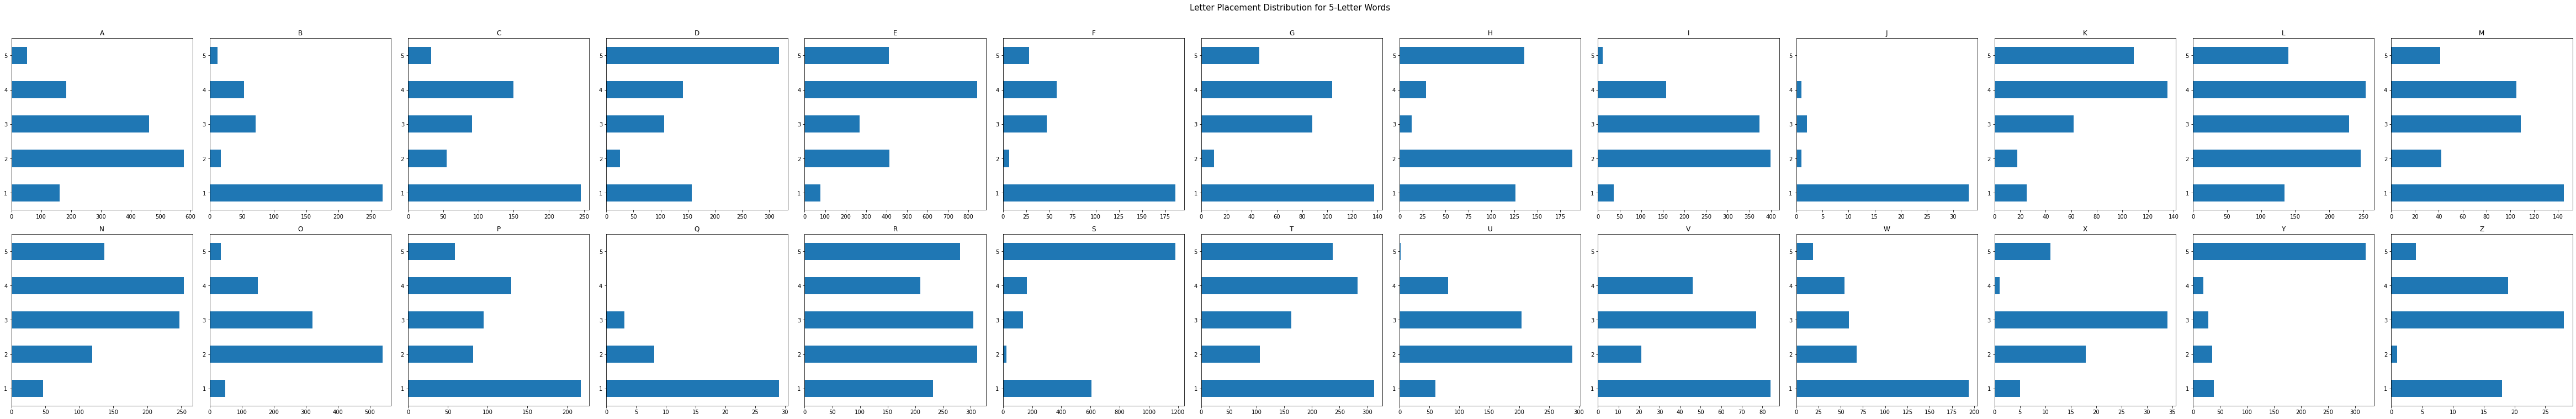

In [ ]:
# results
resolution = 250
nrows = 4 + 1
ncols = 6
nrows = 2
ncols = 13
sub_plot_size = 5
fig,ax = plt.subplots(nrows,ncols,figsize=(ncols*sub_plot_size,nrows*sub_plot_size))#,sharex=True) ## don't share_x because we don't need to compare between letters but between positions
counter = 0
results.rename(columns={'first letter':1, 'second letter':2, 'third letter':3,
       'fourth letter':4, 'fifth letter':5},inplace=True)
for i in range(nrows):
    for j in range(ncols):
        if counter <= 26 - 1:
            letter = alphabet_list[counter]
            ##['fifth letter','fourth letter','third letter','second letter','first letter']==[5,4,3,2,1]
            results[[1,2,3,4,5]].T[letter].plot(kind='bar',title=letter.upper(),ax=ax[i][j])
        counter += 1

plt.tight_layout()
fig.suptitle('Letter Placement Distribution for 5-Letter Words',y=1.05,size=15)
# plt.savefig(p + f'Letter Placement Distribution for 5-Letter Words {nrows}X{ncols} res={resolution}.png',dpi=resolution)
plt.show()

# Find a 6-letter bank / or a bigger 5-letter bank?